# Figure 2: a reproducible seed-42 correspondence

**Yuan (2025)**, *Artificial intelligence in language learning: biometric feedback and adaptive reading for improved comprehension and reduced anxiety*. [DOI: 10.1057/s41599-025-04878-w](https://doi.org/10.1057/s41599-025-04878-w), Figure 2, PDF p.9.

This demonstration extracts centers **from the supplied original JPEG**, generates a fixed candidate, and compares unordered **paired (x,y) locations**.

The hypothesis was identified exploratorily in a larger audit aided by an AI coding assistant.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # portable static output; no GUI backend required
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from IPython.display import display, Image
from extract_points import extract

OUT = Path("outputs")
# The extraction runs before, and independently of, the candidate generator.
observed, calibration = extract(Path("figure2_original.jpeg"), OUT)
display(observed.groupby("group").agg(
    detected=("point_id", "size"),
    fixation_mean_ms=("fixation_ms", "mean"),
    fixation_sd_ms=("fixation_ms", "std"),
    regression_mean=("regression_count", "mean")))
display(observed.head())

,detected,fixation_mean_ms,fixation_sd_ms,regression_mean
group,,,,
blue,100,218.297857,13.483832,4.046147
red,96,281.894770,16.255682,6.956630


,group,point_id,x_pixel,y_pixel,fixation_ms,regression_count,center_uncertainty_px,fixation_uncertainty_ms,regression_uncertainty,detection_score
0,blue,1,646.953253,1039.186391,225.344583,3.141093,3.0,0.318170,0.031835,0.965034
1,blue,2,637.049031,1042.040076,224.444232,3.115137,3.0,0.318170,0.031835,0.965034
2,blue,3,502.863865,891.890065,212.246027,4.480858,3.0,0.318170,0.031835,0.963577
3,blue,4,762.754809,1089.989932,235.871612,2.678999,1.5,0.181812,0.018191,0.962120
4,blue,5,489.030725,1115.274914,210.988515,2.449014,3.0,0.318170,0.031835,0.959176


## 1. Check the image-only extraction

Green circles mark candidate cross centers. Overlapping diagonal strokes can produce false peaks or hide real centers: 100 blue and 96 red detections do not establish the true observation count. 

Pixels use the upper-left origin (x right, y down). Axis coordinates use the numerical labels in the figure. A linear fit to seven x ticks and eight y ticks gives approximately 11 pixels/ms and −110 pixels/regression. The CSV preserves pairing and includes conservative measurement allowances. The image is 1950 × 1296 pixels, directly extracted from the paper, not a rendered page.

x_pixel = 11.000402531 * fixation_ms -1831.927866139
y_pixel = -109.941945021 * regression_count +1384.524313136


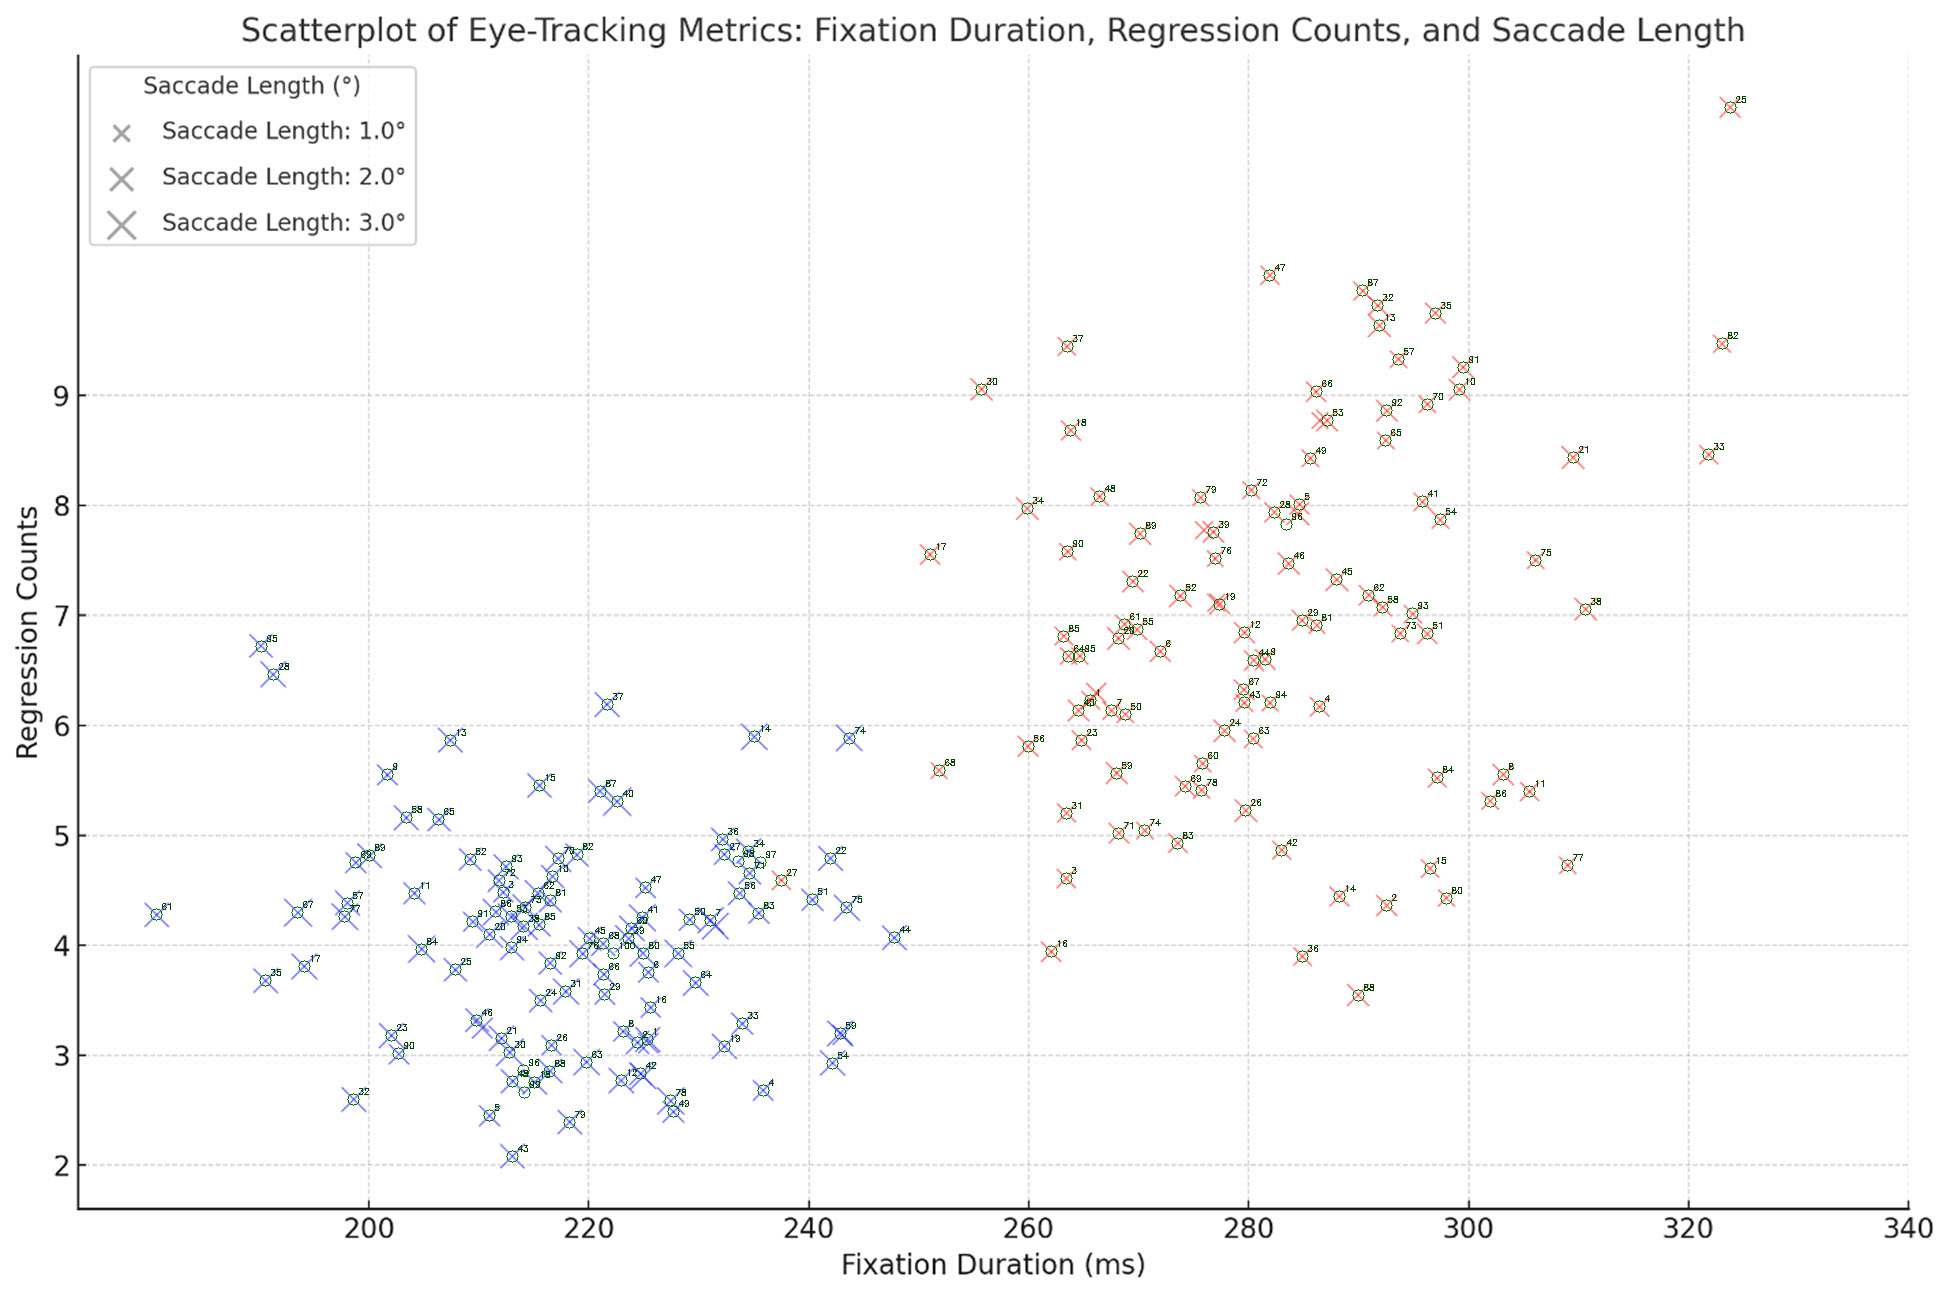

In [2]:
display(Image(filename=str(OUT / "detected_points.png"), width=975))
print("x_pixel = %.9f * fixation_ms %+.9f" % (
    calibration["pixel_x_per_ms"], calibration["pixel_x_intercept"]))
print("y_pixel = %.9f * regression_count %+.9f" % (
    calibration["pixel_y_per_regression"], calibration["pixel_y_intercept"]))

## 2. Generate the fixed candidate

This is **legacy NumPy `RandomState(42)`**, equivalent to the corresponding module calls after `np.random.seed(42)`. Modern `default_rng(42)` is a different sequence.

The 100 uniform draws **between the groups are essential**: they correspond to the candidate's marker-size generation and advance the stream before the red coordinates. Uniform draws are retained below, but the absolute conversion to saccade length is not assumed. Each simulated group contains 100 paired points. No affine parameters are fitted to the extracted points here.

In [3]:
rng = np.random.RandomState(42)
x_blue = rng.normal(220, 15, 100)
y_blue = rng.normal(4, 1, 100)
u_blue = rng.uniform(0, 1, 100)
x_red = rng.normal(280, 20, 100)
y_red = rng.normal(7, 1.5, 100)
u_red = rng.uniform(0, 1, 100)

simulated = pd.concat([
    pd.DataFrame(dict(group=group, rng_index=np.arange(100),
                      fixation_ms=x, regression_count=y, uniform_size_draw=u))
    for group, x, y, u in [
        ("blue", x_blue, y_blue, u_blue),
        ("red", x_red, y_red, u_red)]
], ignore_index=True)
# Project predictions into the actual calibrated image-pixel coordinate system.
simulated["x_pixel"] = (simulated.fixation_ms * calibration["pixel_x_per_ms"]
                         + calibration["pixel_x_intercept"])
simulated["y_pixel"] = (simulated.regression_count * calibration["pixel_y_per_regression"]
                         + calibration["pixel_y_intercept"])
simulated.to_csv(OUT / "simulated_points.csv", index=False)

## 3. Match paired locations, allowing unmatched points

Hungarian assignment minimizes squared 2D pixel distance. One dummy slot per detected point costs 3²; choosing a dummy leaves that detection unmatched. Generated points may also remain unmatched. This avoids forcing false peaks onto distant predictions. There is no sorting of x and y separately and no arbitrary re-pairing.

We report 1, 2, 3 and 5 pixels tresholds below. Summary residuals describe matched pairs only; all unmatched detections and predictions are explicitly retained and displayed. Residuals are recovered minus simulated. Image-y residuals point downwards; regression-unit residuals have the opposite sign.

In [4]:
def assign(observed_xy, simulated_xy, tolerance_px=3):
    distances = cdist(observed_xy, simulated_xy)
    cost = np.column_stack([
        distances ** 2,
        np.full((len(observed_xy), len(observed_xy)), tolerance_px ** 2)
    ])
    rows, columns = linear_sum_assignment(cost)
    real = columns < len(simulated_xy)
    return rows[real], columns[real]

pairs, unmatched_observed, unmatched_simulated, summaries, sensitivities = [], [], [], [], []
for group in ["blue", "red"]:
    obs = observed[observed.group == group].reset_index(drop=True)
    sim = simulated[simulated.group == group].reset_index(drop=True)
    pixel_columns = ["x_pixel", "y_pixel"]
    oi, si = assign(obs[pixel_columns], sim[pixel_columns])
    residual_px = obs.loc[oi, pixel_columns].to_numpy() - sim.loc[si, pixel_columns].to_numpy()
    residual_units = (obs.loc[oi, ["fixation_ms", "regression_count"]].to_numpy()
                      - sim.loc[si, ["fixation_ms", "regression_count"]].to_numpy())
    distance = np.linalg.norm(residual_px, axis=1)
    pairs.append(pd.DataFrame(dict(
        group=group, point_id=obs.loc[oi, "point_id"].to_numpy(),
        rng_index=sim.loc[si, "rng_index"].to_numpy(),
        dx_pixel=residual_px[:, 0], dy_pixel=residual_px[:, 1],
        distance_pixel=distance, dx_ms=residual_units[:, 0],
        dy_regressions=residual_units[:, 1])))
    unmatched_observed.append(obs.drop(oi))
    unmatched_simulated.append(sim.drop(si))
    summaries.append(dict(group=group, detected=len(obs), generated=len(sim),
        matched=len(oi), unmatched_detected=len(obs)-len(oi),
        unmatched_generated=len(sim)-len(si),
        rms_pixel=np.sqrt(np.mean(distance**2)), max_pixel=distance.max(),
        rms_fixation_ms=np.sqrt(np.mean(residual_units[:, 0]**2)),
        rms_regressions=np.sqrt(np.mean(residual_units[:, 1]**2))))
    for tolerance in [1, 2, 3, 5]:
        i, j = assign(obs[pixel_columns], sim[pixel_columns], tolerance)
        sensitivities.append(dict(group=group, tolerance_px=tolerance, matched=len(i)))

pairs = pd.concat(pairs, ignore_index=True)
unmatched_observed = pd.concat(unmatched_observed, ignore_index=True)
unmatched_simulated = pd.concat(unmatched_simulated, ignore_index=True)
summary = pd.DataFrame(summaries)
for name, table in [("matched_pairs", pairs), ("unmatched_detections", unmatched_observed),
                    ("unmatched_predictions", unmatched_simulated), ("matching_summary", summary)]:
    table.to_csv(OUT / f"{name}.csv", index=False)
display(summary.round(6))
display(pd.DataFrame(sensitivities).pivot(index="tolerance_px", columns="group", values="matched"))

,group,detected,generated,matched,unmatched_detected,unmatched_generated,rms_pixel,max_pixel,rms_fixation_ms,rms_regressions
0,blue,100,100,95,5,5,0.242692,0.724079,0.018091,0.001263
1,red,96,100,95,1,5,0.371500,0.745890,0.015791,0.002987


group,blue,red
tolerance_px,,
1,95,95
2,95,95
3,95,95
5,95,95


## 4. Correspondence and pixel-scale residuals

Left: all recovered centers and all generated points, with unmatched points outlined separately. 

Right: only assigned pairs, zoomed to ±1 original-image pixel. A faint unit circle marks 1 pixel; it is smaller than the 3-pixel matching threshold. No residual magnification is applied on the coordinate overlays.

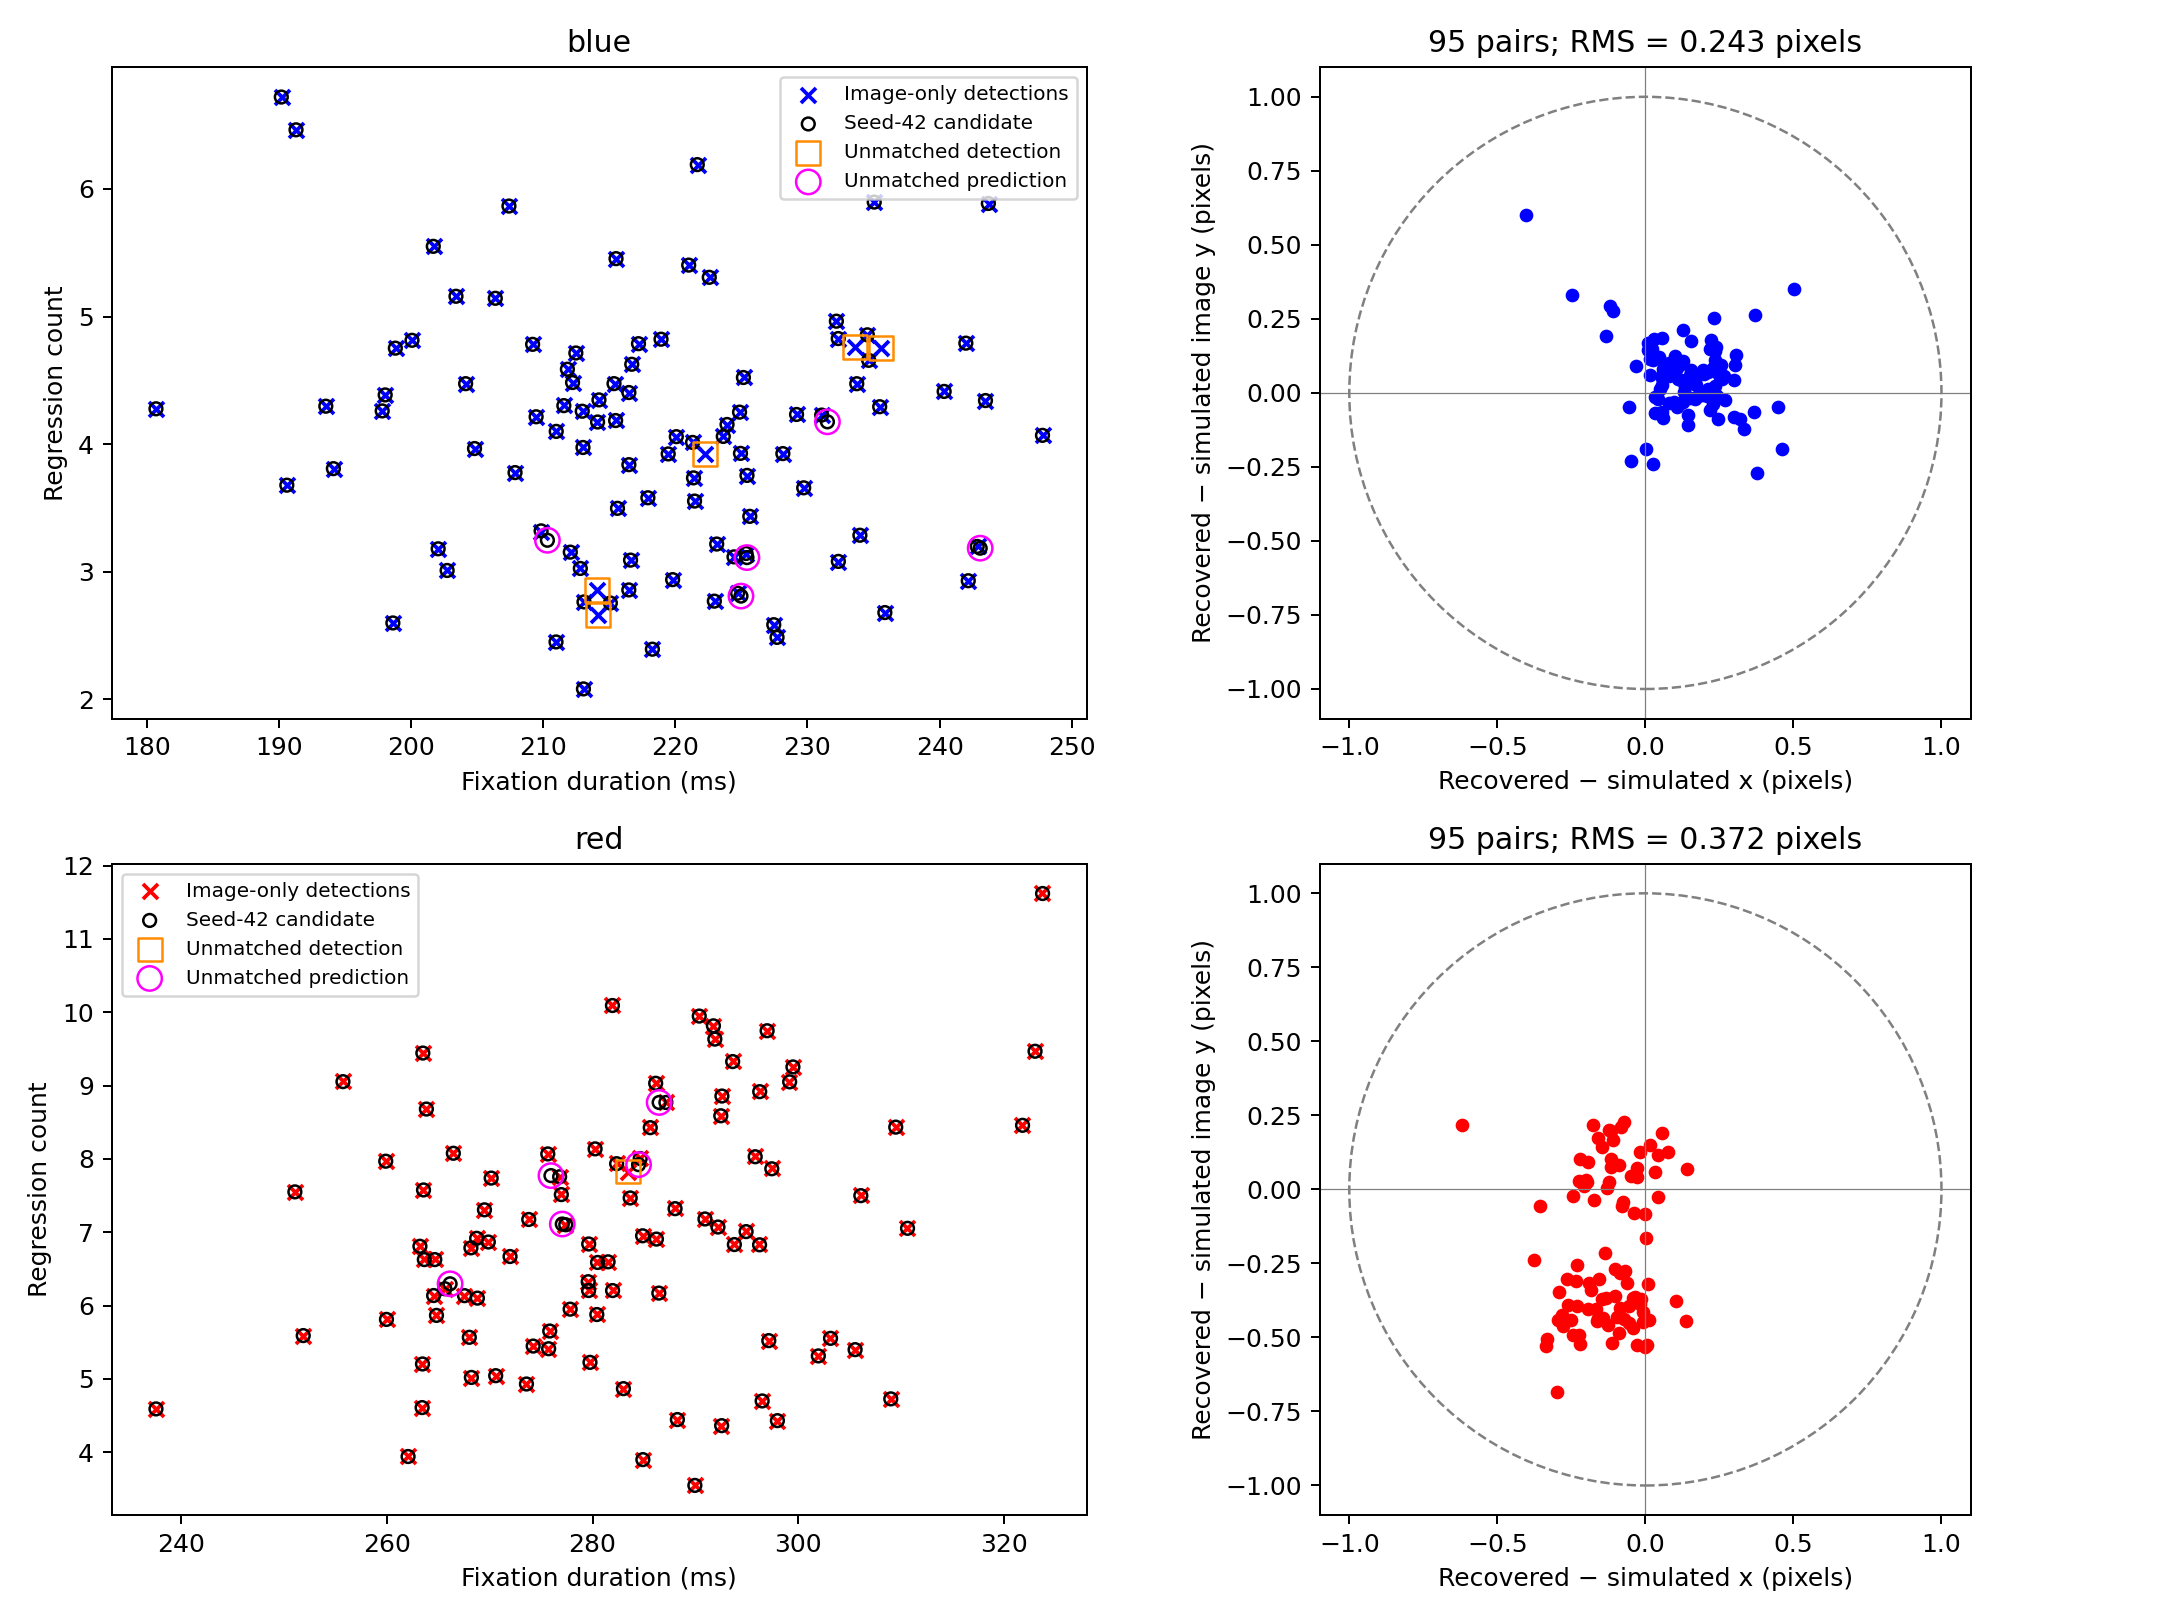

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, group in enumerate(["blue", "red"]):
    obs = observed[observed.group == group]
    sim = simulated[simulated.group == group]
    match = pairs[pairs.group == group]
    unmatched_o = unmatched_observed[unmatched_observed.group == group]
    unmatched_s = unmatched_simulated[unmatched_simulated.group == group]
    ax = axes[row, 0]
    ax.scatter(obs.fixation_ms, obs.regression_count, marker="x", c=group,
               label="Image-only detections")
    ax.scatter(sim.fixation_ms, sim.regression_count, facecolors="none", edgecolors="black",
               s=26, label="Seed-42 candidate")
    ax.scatter(unmatched_o.fixation_ms, unmatched_o.regression_count, marker="s", s=90,
               facecolors="none", edgecolors="darkorange", label="Unmatched detection")
    ax.scatter(unmatched_s.fixation_ms, unmatched_s.regression_count, s=95,
               facecolors="none", edgecolors="magenta", label="Unmatched prediction")
    ax.set(xlabel="Fixation duration (ms)", ylabel="Regression count", title=group)
    ax.legend(fontsize=8)
    ax = axes[row, 1]
    ax.scatter(match.dx_pixel, match.dy_pixel, c=group, s=20)
    ax.add_patch(plt.Circle((0, 0), 1, color="gray", fill=False, linestyle="--"))
    ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
    rms = summary.loc[summary.group == group, "rms_pixel"].iloc[0]
    ax.set(xlabel="Recovered − simulated x (pixels)",
           ylabel="Recovered − simulated image y (pixels)",
           title=f"{len(match)} pairs; RMS = {rms:.3f} pixels",
           xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal")
fig.tight_layout()
fig.savefig(OUT / "correspondence.png", dpi=180)
plt.close(fig)
display(Image(filename=str(OUT / "correspondence.png"), width=1000))

## 5. How small are the differences in the plotted units?

The histograms express matched residuals in milliseconds and regression counts. They do not show the six unmatched detected peaks or ten unmatched generated locations; those remain in the previous figure and the exported CSVs. Close-pair errors are much smaller than marker dimensions and the conservative digitisation allowances.

190 paired matches; maximum discrepancy 0.746 pixels.
Unmatched: 6 detections and 10 predictions.


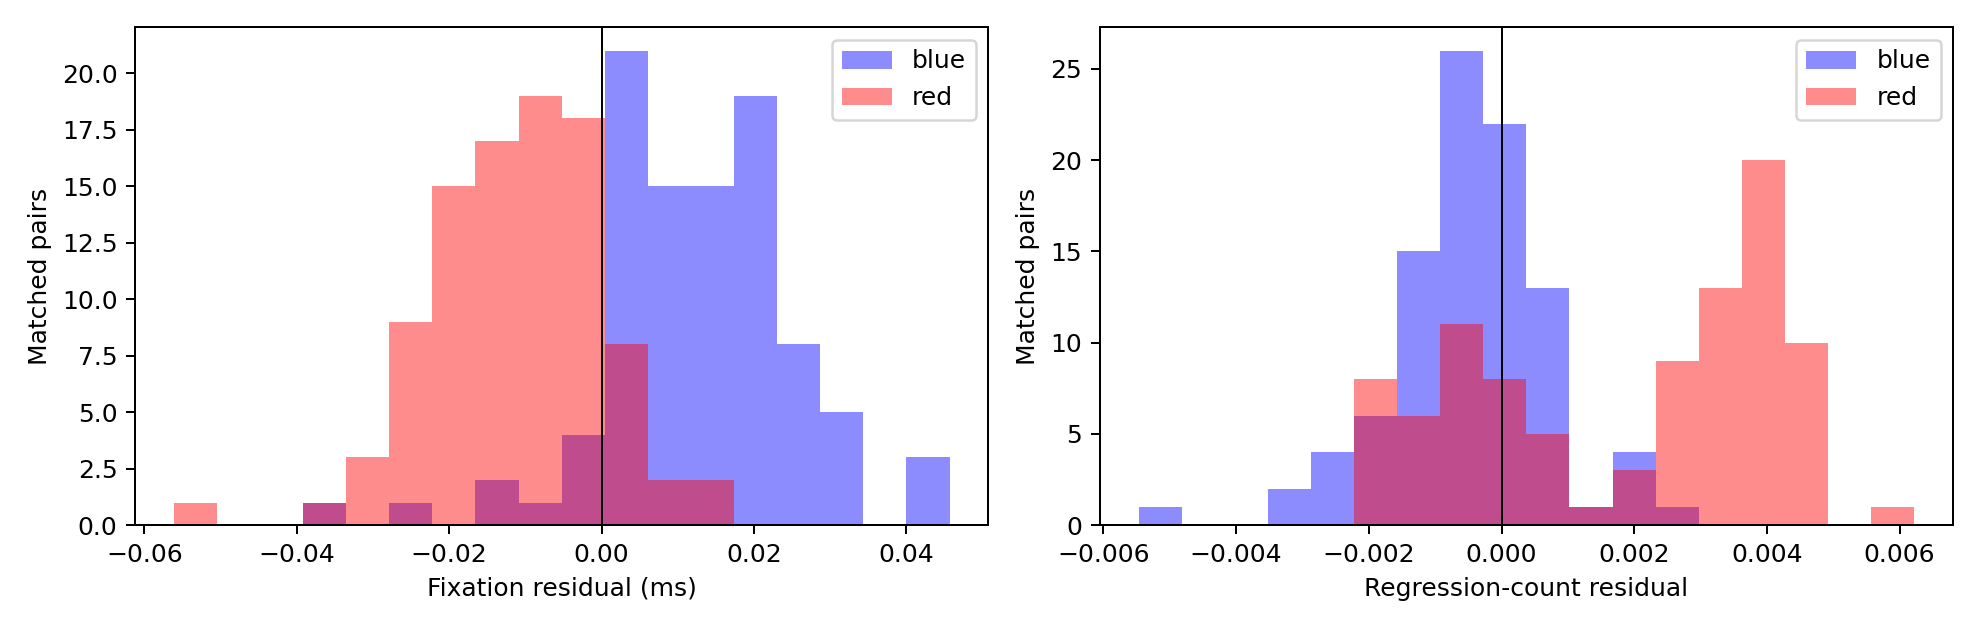

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, column, label in zip(axes, ["dx_ms", "dy_regressions"],
                           ["Fixation residual (ms)", "Regression-count residual"]):
    bins = np.linspace(pairs[column].min(), pairs[column].max(), 19)
    for group in ["blue", "red"]:
        ax.hist(pairs.loc[pairs.group == group, column], bins=bins,
                color=group, alpha=.45, label=group)
    ax.axvline(0, color="black", lw=.8)
    ax.set(xlabel=label, ylabel="Matched pairs")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "residuals_in_axis_units.png", dpi=180)
plt.close(fig)
display(Image(filename=str(OUT / "residuals_in_axis_units.png"), width=1000))
print(f"{len(pairs)} paired matches; maximum discrepancy {pairs.distance_pixel.max():.3f} pixels.")
print(f"Unmatched: {len(unmatched_observed)} detections and {len(unmatched_simulated)} predictions.")

## Interpretation and limits

The tested environment recovers **95 matches per group**, all within one original-image pixel. This is a correspondence between paired locations, not merely similar Gaussian distributions. Original raster/JPEG quantisation, tick calibration and overlap explain why recovered values are approximate rather than numerically identical.

No observations are discarded from the saved extraction, and no model-assisted centers are added. Counts and individual detections can vary with image-processing versions and settings; this package fixes and documents the settings. The unmatched points are not by themselves evidence of omitted or fabricated observations.

The candidate was selected in an earlier exploratory audit, run with the help of an AI coding assistant. This minimal notebook does not reproduce its full model search. It demonstrates a specific synthetic construction compatible with the published figure.